# BE1 . Data Science
### Identification des utilisateurs de Copilote à partir de leurs traces

**Bureau d'études réalisé par :**

* Hajar Zarguan
* Valentine Ponce
* Guillaume Sumian

### Objectif du projet

Ce projet vise à identifier les utilisateurs de Copilote à partir de leurs traces, en suivant trois étapes principales :

|  Étape | Description                                           |
| :----: | ----------------------------------------------------- |
| **01** | Analyse exploratoire des données                      |
| **02** | Construction et évaluation du modèle d'identification |
| **03** | Optimisation du modèle et analyse des performances    |


## Préparation : bibliothèques et lecture des données

In [ ]:
from pathlib import Path
import re
import math
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.preprocessing import normalize, OneHotEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


# Style
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({
    "figure.figsize": (9.5, 4.5), "figure.dpi": 70,
    "axes.spines.top": False, "axes.spines.right": True,
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "right",
    "axes.edgecolor": "#bccffb", "grid.color": "#c6dbdd",
})
BLEU, ORANGE, GRIS = "#68baed", "#fa7e4d", "#a8a692"
COULEURS = ["#388cf2", "#f25313", "#1fc428", "#fabc2a", "#fc79bf", "#2cc72c", "#8271e3", "#eb6160"]
GRAINE = 42 #Sans graine fixe SI ON relance le notebook , ce dernier  changerait le découpage  d' apprentissage et la validation. L’exactitude passerait par exemple de 0,927 à 0,931, le t-SNE aurait une autre forme, et le meilleur réglage de l’optimisation pourrait même changer.

**Pour la  lecture :** nous avons constatés que les lignes n'ont pas toutes le même nombre de champs et donc un `pd.read_csv` classique ne convient pas. On lit donc le fichier **ligne par ligne**, sans le charger d'un bloc, et chaque ligne devient une session.

Un jeton est soit un marqueur temporel (`t5`, `t10`… : 5 s, 10 s… écoulées depuis le début de la session),
soit une action de la forme `Nom(écran)<configuration>$chaîne$1`, où tout ce qui suit le nom est facultatif
(le `1` final signale une modification de fiche).

In [2]:
def trouver(nom):
    """Cherche le fichier dans ../data (notebook lancé depuis scr/) ou data/, sans tenir compte des majuscules."""
    for dossier in [Path("../data"), Path("data")]:
        if dossier.is_dir():
            for f in dossier.iterdir():
                if f.name.lower() == nom.lower():
                    return f
    raise FileNotFoundError(f"{nom} introuvable dans ../data ni dans data")


def lire_sessions(fichier, avec_utilisateur):
    """Lit le fichier ligne par ligne. Renvoie la liste des sessions et le nombre de lignes vides."""
    sessions, lignes_vides = [], 0
    with open(fichier, encoding="utf-8-sig") as f:
        for ligne in f:
            ligne = ligne.strip()
            if not ligne:
                lignes_vides += 1
                continue
            champs = ligne.split(",")
            if avec_utilisateur:
                sessions.append({"util": champs[0], "navigateur": champs[1], "jetons": champs[2:]})
            else:
                sessions.append({"navigateur": champs[0], "jetons": champs[1:]})
    return sessions, lignes_vides


RE_TEMPS = re.compile(r"^t(\d+)$")
RE_ACTION = re.compile(r"^(?P<nom>[^(<$]*?)(?:\((?P<ecran>[^)]*)\))?(?:<(?P<conf>[^>]*)>)?(?:\$(?P<chaine>[^$]*)\$)?(?P<modif>1)?$")


def decrire_session(jetons):
    """Transforme la liste des jetons d'une session en quelques indicateurs simples."""
    types, actions, ecrans, configs, chaines = [], [], [], [], []
    fenetres = Counter()                 # nombre d'actions dans chaque fenêtre de 5 secondes
    t, n_marqueurs, n_vides, n_non_conformes = 0, 0, 0, 0
    for jeton in jetons:
        jeton = jeton.strip()
        if not jeton:
            n_vides += 1
            continue
        m = RE_TEMPS.match(jeton)
        if m:                            # marqueur temporel
            n_marqueurs += 1
            t = max(t, int(m.group(1)))
            continue
        m = RE_ACTION.match(jeton)       # action
        if m is None or not m["nom"].strip():
            n_non_conformes += 1
            nom = jeton
        else:
            nom = m["nom"].strip()
            if m["ecran"]:
                ecrans.append(m["ecran"])
            if m["conf"]:
                configs.append(m["conf"])
            if m["chaine"]:
                chaines.append(m["chaine"])
        types.append(nom.replace(" ", "_"))          # un symbole sans espace par action
        actions.append(jeton.replace(" ", "_"))
        fenetres[t] += 1

    n = len(types)
    n_fenetres = t // 5 + 1
    frequences = Counter(types)
    return {
        "n_actions": n,
        "n_marqueurs": n_marqueurs,
        "duree_s": t,                                            # durée estimée = dernier marqueur
        "cadence": n / max(t, 5),                                # actions par seconde
        "nb_types": len(frequences),
        "ratio_distinct": len(set(actions)) / max(n, 1),         # part d'actions différentes
        "entropie": -sum(c / n * math.log2(c / n) for c in frequences.values()) if n else 0.0,
        "nb_ecrans": len(set(ecrans)),
        "actions_par_fenetre": list(fenetres.values()) + [0] * (n_fenetres - len(fenetres)),
        "ecrans": ecrans, "configs": configs, "chaines": chaines,
        "doc_actions": " ".join(actions),                        # texte pour le TF-IDF
        "doc_types": " ".join(types),
        "n_champs_vides": n_vides, "n_non_conformes": n_non_conformes,
    }


fichier_train = trouver("train.csv")
train_brut, train_lignes_vides = lire_sessions(fichier_train, avec_utilisateur=True)
train = pd.DataFrame([{"util": s["util"], "navigateur": s["navigateur"], "empreinte": hash(tuple(s["jetons"])),
                       **decrire_session(s["jetons"])} for s in train_brut])
train["log_actions"] = np.log1p(train["n_actions"])
train["log_duree"] = np.log1p(train["duree_s"])
print(f"{fichier_train.name} : {len(train):,} sessions chargées (toutes les lignes du fichier).")

train.csv : 3,279 sessions chargées (toutes les lignes du fichier).


---
# Section 1 . Exploration des données

## 1.1 Audit des données
Chaque ligne du tableau indique **ce qui est vérifié** , le **résultat** et **ce que ce résultat signifie** pour la suite.

In [3]:
effectifs = train["util"].value_counts()
n_sessions = len(train)
non_conformes = int(train["n_non_conformes"].sum())
champs_vides = int(train["n_champs_vides"].sum())
sans_action = int((train["n_actions"] == 0).sum())
doublons = int(train.duplicated(["util", "navigateur", "empreinte"]).sum())
toutes_actions = Counter(a for doc in train["doc_actions"] for a in doc.split())
tous_types = Counter(a for doc in train["doc_types"] for a in doc.split())


def sens(valeur, si_zero, sinon):
    return si_zero if valeur == 0 else sinon


audit = pd.DataFrame([
    ("Nombre de sessions", f"{n_sessions:,}", "Taille de l'échantillon d'apprentissage : chaque session est un exemple."),
    ("Nombre d'utilisateurs", f"{len(effectifs)}", "Nombre de classes que le modèle devra distinguer."),
    ("Sessions par utilisateur (min / médiane / max)", f"{effectifs.min()} / {effectifs.median():.0f} / {effectifs.max()}",
     "Peu de sessions pour certains utilisateurs : ils seront plus difficiles à reconnaître."),
    ("Navigateurs distincts", f"{train['navigateur'].nunique()}", "Variable catégorielle à encoder (un indicateur par navigateur)."),
    ("Lignes vides", f"{train_lignes_vides}", sens(train_lignes_vides, "Aucune ligne vide.", "Lignes ignorées à la lecture.")),
    ("Sessions sans aucune action", f"{sans_action}", sens(sans_action, "Toutes les sessions contiennent au moins une action.",
                                                           "Sessions vides : impossibles à attribuer à partir des actions.")),
    ("Valeurs manquantes (champs vides)", f"{champs_vides}", sens(champs_vides, "Aucune valeur manquante : pas d'imputation à faire.",
                                                                  "Champs vides ignorés lors de la lecture.")),
    ("Jetons qui ne respectent pas le format attendu", f"{non_conformes}",
     sens(non_conformes, "Le format Nom(écran)<config>$chaîne$1 est respecté partout : la lecture est fiable.",
          "Jetons gardés tels quels ; à examiner s'ils sont nombreux.")),
    ("Sessions en double (même utilisateur, même trace)", f"{doublons}",
     sens(doublons, "Aucun doublon.", "Doublons conservés : une même tâche répétée peut être légitime.")),
    ("Actions par session (min / médiane / max)",
     f"{train['n_actions'].min()} / {train['n_actions'].median():.0f} / {train['n_actions'].max():,}",
     "Longueurs très variables : il faudra normaliser les comptages."),
    ("Types d'action distincts", f"{len(tous_types)}", "Vocabulaire réduit : le « nom » de l'action (clic, saisie…)."),
    ("Jetons d'action distincts", f"{len(toutes_actions):,}", "Vocabulaire riche : nom + écran + configuration + chaîne."),
], columns=["Vérification", "Résultat", "Ce que cela signifie"])

with pd.option_context("display.max_colwidth", None):
    display(audit.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Vérification,Résultat,Ce que cela signifie
Nombre de sessions,"3,279",Taille de l'échantillon d'apprentissage : chaque session est un exemple.
Nombre d'utilisateurs,247,Nombre de classes que le modèle devra distinguer.
Sessions par utilisateur (min / médiane / max),4 / 12 / 75,Peu de sessions pour certains utilisateurs : ils seront plus difficiles à reconnaître.
Navigateurs distincts,4,Variable catégorielle à encoder (un indicateur par navigateur).
Lignes vides,0,Aucune ligne vide.
Sessions sans aucune action,1,Sessions vides : impossibles à attribuer à partir des actions.
Valeurs manquantes (champs vides),0,Aucune valeur manquante : pas d'imputation à faire.
Jetons qui ne respectent pas le format attendu,9,Jetons gardés tels quels ; à examiner s'ils sont nombreux.
"Sessions en double (même utilisateur, même trace)",0,Aucun doublon.
Actions par session (min / médiane / max),"0 / 340 / 11,977",Longueurs très variables : il faudra normaliser les comptages.


## 1.2 Utilisateurs et sessions
### Présence et activité des utilisateurs

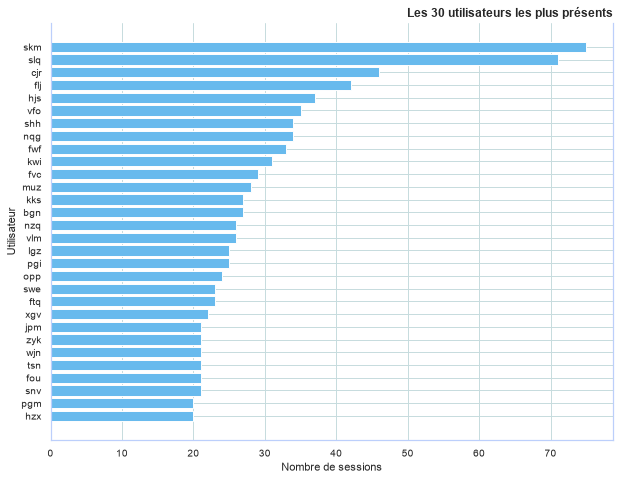

In [4]:
top30 = effectifs.head(30)
plt.figure(figsize=(9, 7))
plt.barh(top30.index[::-1], top30.values[::-1], color=BLEU)
plt.title("Les 30 utilisateurs les plus présents")
plt.xlabel("Nombre de sessions")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

Chaque barre donne le nombre de sessions d'un utilisateur. Les utilisateurs les plus présents fournissent beaucoup
d'exemples au modèle : ce sont les plus faciles à apprendre.

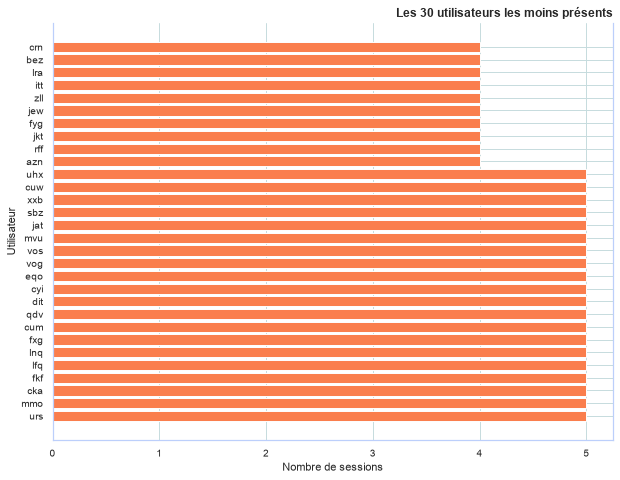

In [5]:
bas30 = effectifs.tail(30)
plt.figure(figsize=(9, 7))
plt.barh(bas30.index, bas30.values, color=ORANGE)
plt.title("Les 30 utilisateurs les moins présents")
plt.xlabel("Nombre de sessions")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

À l'opposé, ces utilisateurs n'ont que quelques sessions. Le modèle aura peu d'exemples pour apprendre leur façon de
travailler : c'est sur eux que l'on attend le plus d'erreurs.

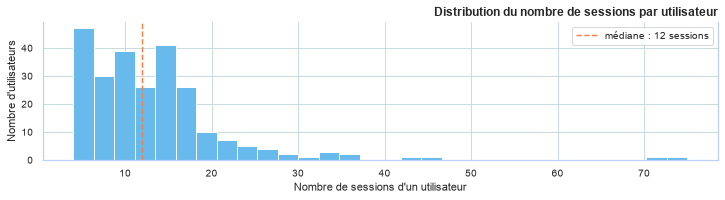

Un utilisateur a en médiane 12 sessions ; l'utilisateur le plus présent en a 75.


In [6]:
plt.figure()
plt.hist(effectifs.values, bins=30, color=BLEU, edgecolor="white")
plt.axvline(effectifs.median(), color=ORANGE, linestyle="--", label=f"médiane : {effectifs.median():.0f} sessions")
plt.title("Distribution du nombre de sessions par utilisateur")
plt.xlabel("Nombre de sessions d'un utilisateur")
plt.ylabel("Nombre d'utilisateurs")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Un utilisateur a en médiane {effectifs.median():.0f} sessions ; l'utilisateur le plus présent en a {effectifs.max()}.")

La plupart des utilisateurs ont peu de sessions et quelques-uns en ont beaucoup et donc les classes sont **déséquilibrées**.
On utilisera un découpage de chaque utilisateur garde sa proportion et on regardera aussi le F1 macro,
qui donne le même poids à chaque utilisateur.

### Navigateurs utilisés

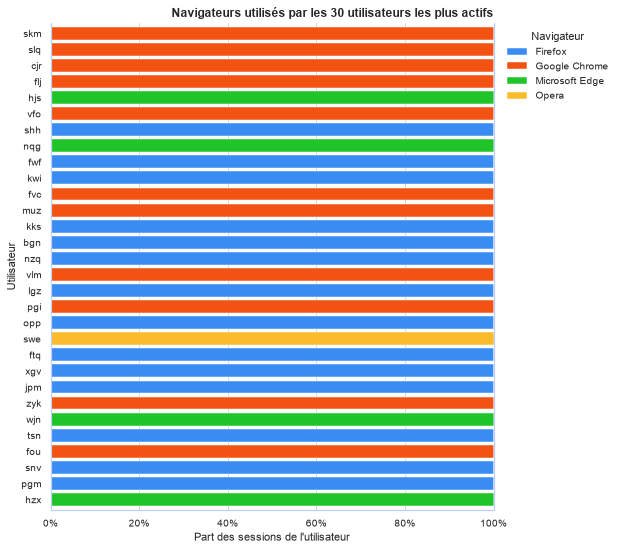

In [7]:
navigateurs = train["navigateur"].value_counts().index
parts_nav = pd.crosstab(train["util"], train["navigateur"], normalize="index").loc[top30.index, navigateurs]

ax = parts_nav.plot(kind="barh", stacked=True, figsize=(9, 8), width=0.8,
                    color=COULEURS[:len(navigateurs)], edgecolor="white", linewidth=0.5)
ax.invert_yaxis()
ax.set_title("Navigateurs utilisés par les 30 utilisateurs les plus actifs")
ax.set_xlabel("Part des sessions de l'utilisateur")
ax.set_ylabel("Utilisateur")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title="Navigateur", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

Chaque barre représente 100 % des sessions d'un utilisateur, découpées selon le navigateur utilisé.
On peut assumer que les utilisateurs semblent fidèles à leurs navigateurs

### Longueur des sessions
La longueur d'une session est son nombre d'actions ... L'échelle est logarithmique, car les longueurs vont de quelques
actions à plusieurs milliers

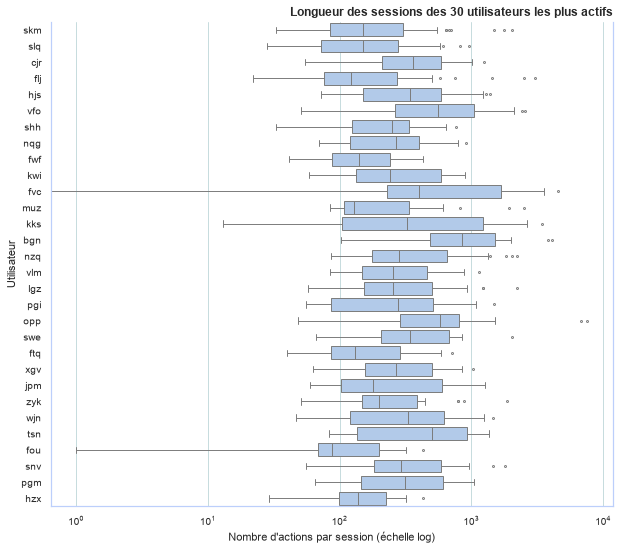

In [8]:
plt.figure(figsize=(9, 8))
sns.boxplot(data=train[train["util"].isin(top30.index)], y="util", x="n_actions", order=top30.index,
            color="#a9c9f2", fliersize=2, linewidth=1)
plt.xscale("log")
plt.title("Longueur des sessions des 30 utilisateurs les plus actifs")
plt.xlabel("Nombre d'actions par session (échelle log)")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

Une boîte résume les sessions d'un utilisateur le trait central est la médiane, la boîte contient la moitié des
sessions, les points sont des sessions inhabituelles. Des boîtes placées à des hauteurs différentes indiquent que
certains utilisateurs font des sessions plus longues que d'autres.

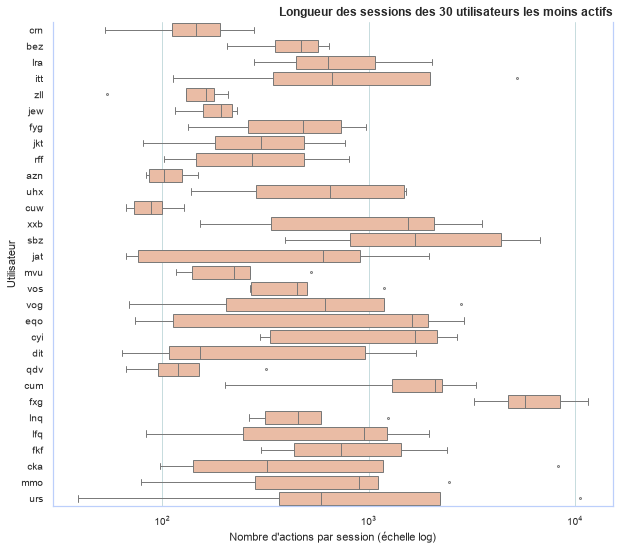

In [9]:
plt.figure(figsize=(9, 8))
sns.boxplot(data=train[train["util"].isin(bas30.index)], y="util", x="n_actions", order=bas30.index[::-1],
            color="#f5b899", fliersize=2, linewidth=1)
plt.xscale("log")
plt.title("Longueur des sessions des 30 utilisateurs les moins actifs")
plt.xlabel("Nombre d'actions par session (échelle log)")
plt.ylabel("Utilisateur")
plt.tight_layout()
plt.show()

Même lecture pour les utilisateurs les moins présents. Avec peu de sessions, une boîte est moins fiable : une seule
session longue suffit à la déplacer.

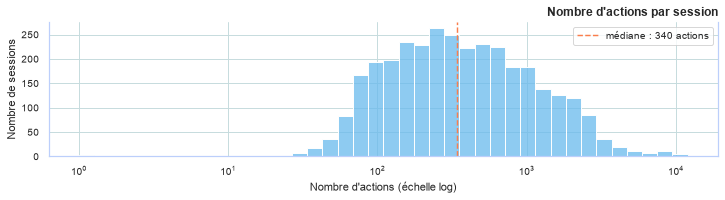

In [10]:
plt.figure()
sns.histplot(train["n_actions"].clip(lower=1), bins=40, log_scale=True, color=BLEU, edgecolor="white")
plt.axvline(train["n_actions"].median(), color=ORANGE, linestyle="--", label=f"médiane : {train['n_actions'].median():.0f} actions")
plt.title("Nombre d'actions par session")
plt.xlabel("Nombre d'actions (échelle log)")
plt.ylabel("Nombre de sessions")
plt.legend()
plt.tight_layout()
plt.show()

La plupart des sessions comptent quelques dizaines à quelques centaines d'actions, mais certaines en contiennent
des milliers Pour le modèle, on utilisera donc des **fréquences** d'actions normalisées plutôt que des comptages
bruts : sinon, les longues sessions écraseraient les courtes.

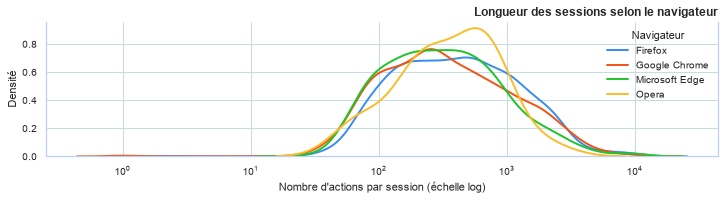

In [11]:
plt.figure()
for couleur, nav in zip(COULEURS, navigateurs):
    sns.kdeplot(train.loc[train["navigateur"] == nav, "n_actions"].clip(lower=1), log_scale=True,
                color=couleur, linewidth=2, label=nav)
plt.title("Longueur des sessions selon le navigateur")
plt.xlabel("Nombre d'actions par session (échelle log)")
plt.ylabel("Densité")
plt.legend(title="Navigateur", frameon=False)
plt.tight_layout()
plt.show()